**Environment setup:** Install the required NLP/model dependencies in Cell #1, then proceed directly to the notebook. No mandatory version-checking cell or routine restart. If Colab reports a binary compatibility error after package installation, restart the runtime once.


# L6 / E17 — MiniLM 384D + GMM

**Stage 3 | GMM | 14,639 airline tweets**

Standalone Google Colab notebook. Generate fresh representations from the **redacted, text-only** CSV. Never load historical L1–L5 output matrices or cluster assignments. Save the new assignments **before** loading human sentiment annotations. Enter the labelled CSV path **only in Cell #9**.

**Research status:** This is an exploratory follow-up informed by earlier sentiment results, not an untouched independent evaluation. The same 14,639 tweet corpus and K=3 are retained; this does not prove generalization or K=3 optimality.

In [1]:
# 1 — Install dependencies for E17 (MiniLM + GMM)
%pip install -q sentence-transformers emoji num2words wordninja wordfreq symspellpy vaderSentiment gensim

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


**Run sequentially.** Model packages and remote checkpoints may change; the notebook records installed versions and model IDs. No labelled source is used before Cell #9.

In [2]:
# 2 — Input and output locations: text-only clustering source
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
INPUT_CSV = Path('/content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv')
OUTPUT_DIR = Path('/content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E17')
assert INPUT_CSV.is_file(), f'Missing redacted text CSV: {INPUT_CSV}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Clustering input:', INPUT_CSV)
print('Outputs:', OUTPUT_DIR)

Mounted at /content/drive
Clustering input: /content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv
Outputs: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E17


In [3]:
# 3 — Read text only; preserve original row positions
import numpy as np, pandas as pd, json, hashlib, platform, datetime
import importlib.metadata as im

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

raw = pd.read_csv(INPUT_CSV, usecols=['text'], dtype={'text':'string'})
assert raw['text'].notna().all(), 'Null source tweets'
assert len(raw) == 14639, f'Expected 14639 tweets, got {len(raw)}'
texts = raw['text'].astype(str).tolist()
source_row = np.arange(len(texts), dtype=np.int64)
source_sha = sha256_file(INPUT_CSV)
text_digest = hashlib.sha256(json.dumps(texts, ensure_ascii=False).encode('utf-8')).hexdigest()
print('Tweets:', len(texts), '| SHA256:', source_sha)

Tweets: 14639 | SHA256: a41aeefcff9740c090153f608691d345c84f59084e40f03169c2f667df66578e


### Input preparation

MiniLM receives the **original tweet text**, preserving contractions, punctuation, emojis, airline names and negation. No hand-engineered VADER, punctuation or negation features are added. This tests pretrained contextual sentence embeddings rather than the E0/E6 cleaned-text pipeline. The same 384-dimensional embeddings and L2 normalization are used for all three MiniLM algorithms.

In [4]:
# 4 — Install and load the pretrained MiniLM sentence-embedding model
import torch
from sentence_transformers import SentenceTransformer
MODEL_ID = 'sentence-transformers/all-MiniLM-L6-v2'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
encoder = SentenceTransformer(MODEL_ID, device=DEVICE)
print('Encoder:', MODEL_ID, '| device:', DEVICE)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Encoder: sentence-transformers/all-MiniLM-L6-v2 | device: cpu


In [5]:
# 5 — Minimal preprocessing: preserve the original tweet verbatim
processed_texts = texts.copy()
assert processed_texts == texts
PREPROCESS_CONFIG = {'mode':'raw_original_text','removed_urls':False,'lowercase':False,
                     'emoji_handling':'preserve','negation':'preserve'}
print('Raw tweets preserved:', len(processed_texts))

Raw tweets preserved: 14639


In [6]:
# 6 — Generate fresh MiniLM embeddings; no labels
X = encoder.encode(processed_texts, batch_size=64, show_progress_bar=True,
                   convert_to_numpy=True, normalize_embeddings=True)
X = np.asarray(X, dtype=np.float64)
assert X.shape == (len(texts),384), X.shape
assert np.isfinite(X).all()
print('Embedding matrix:', X.shape, '| mean norm:',np.linalg.norm(X,axis=1).mean())

Batches:   0%|          | 0/229 [00:00<?, ?it/s]

Embedding matrix: (14639, 384) | mean norm: 1.0000000287211028


In [7]:
# 7 — K=3 clustering, without access to sentiment labels
SVD_CONFIG = None
X_model = np.asarray(X,dtype=np.float64)
assert X_model.shape == (len(texts),384)

from sklearn.mixture import GaussianMixture
MODEL_CONFIG = dict(n_components=3, covariance_type='diag', reg_covar=1e-5,
                    n_init=3, max_iter=300, init_params='kmeans', random_state=5001)
model = GaussianMixture(**MODEL_CONFIG)
clusters = model.fit_predict(X_model)
assert model.converged_, 'GMM did not converge; inspect configuration before scoring'
MODEL_DIAGNOSTICS = {'converged':bool(model.converged_), 'iterations':int(model.n_iter_),
                     'lower_bound':float(model.lower_bound_)}
SILHOUETTE_METRIC='euclidean'

assert np.isfinite(X_model).all()
assert len(clusters) == len(texts)
assert set(np.unique(clusters)) == {0,1,2}, 'Three nonempty clusters required'
print('Cluster sizes:',dict(zip(*np.unique(clusters,return_counts=True))))

Cluster sizes: {np.int64(0): np.int64(2581), np.int64(1): np.int64(6283), np.int64(2): np.int64(5775)}


In [8]:
# 8 — Save label-blind assignments BEFORE opening the labelled CSV
import sklearn, scipy
versions = {k:im.version(k) for k in ['numpy','pandas','scikit-learn','scipy']}
manifest = {
    'experiment':'E17', 'stage':'transformer_sentence_embedding',
    'algorithm':'GMM', 'created_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
    'source_csv':INPUT_CSV.name,'source_sha256':source_sha,
    'text_sequence_sha256':text_digest,'n_rows':len(texts),
    'row_alignment':'original positional row, no sort or drop',
    'preprocessing':PREPROCESS_CONFIG,
    'input_shape':list(X.shape),'model_shape':list(X_model.shape),
    'model_config':MODEL_CONFIG,'model_diagnostics':MODEL_DIAGNOSTICS,
    'svd_config':SVD_CONFIG,'silhouette_metric':SILHOUETTE_METRIC,
    'versions':versions,'python':platform.python_version(),
    'cluster_sizes':np.bincount(clusters,minlength=3).tolist(),
}
manifest["encoder_id"] = MODEL_ID
manifest["device"] = DEVICE
manifest["torch_version"] = torch.__version__
assign_path = OUTPUT_DIR/'E17_seed5001_assignments.csv'
pd.DataFrame({'source_row':source_row,'cluster_id':clusters}).to_csv(assign_path,index=False)
manifest['assignments_sha256'] = sha256_file(assign_path)
(OUTPUT_DIR/'E17_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Frozen assignments:',assign_path)

Frozen assignments: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E17/E17_seed5001_assignments.csv


In [9]:
# 9 — ONLY labelled-data access cell: enter path manually
LABEL_CSV = Path('ENTER_LABELLED_CSV_PATH')
assert LABEL_CSV.is_file(), f'Labelled CSV missing: {LABEL_CSV}'
assert LABEL_CSV.resolve() != INPUT_CSV.resolve()
saved = pd.read_csv(assign_path)
assert np.array_equal(saved['source_row'].to_numpy(),source_row)
assert np.array_equal(saved['cluster_id'].to_numpy(),clusters)
assert sha256_file(INPUT_CSV) == source_sha
label_texts = pd.read_csv(LABEL_CSV,usecols=['text'],dtype={'text':'string'})['text']
assert label_texts.notna().all()
assert label_texts.astype(str).tolist() == texts, 'Tweet text/order mismatch'
labels = pd.read_csv(LABEL_CSV,usecols=['airline_sentiment'],
                     dtype={'airline_sentiment':'string'})['airline_sentiment']
assert labels.notna().all() and len(labels)==len(texts)
assert set(labels.unique()) == {'negative','neutral','positive'}
y_true = labels.astype(str).to_numpy()
y_pred = saved['cluster_id'].to_numpy()
print('Verified exact row alignment. Labels now available only for evaluation.')

Verified exact row alignment. Labels now available only for evaluation.


In [10]:
# 10 — External evaluation: mapping-free ARI/NMI; optimal mapping for class metrics
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (adjusted_rand_score,normalized_mutual_info_score,
                             precision_recall_fscore_support,accuracy_score)
CLASSES = ['negative','neutral','positive']
CONTINGENCY = pd.crosstab(pd.Series(y_pred,name='cluster_id'),
                          pd.Series(y_true,name='true_sentiment')).reindex(
                          index=[0,1,2],columns=CLASSES,fill_value=0)
counts = CONTINGENCY.to_numpy()
ri,ci = linear_sum_assignment(-counts)
mapping = {int(r):CLASSES[int(c)] for r,c in zip(ri,ci)}
mapped = np.array([mapping[int(c)] for c in y_pred])
precision,recall,f1,support = precision_recall_fscore_support(
    y_true,mapped,labels=CLASSES,zero_division=0)
per_class = pd.DataFrame({'sentiment':CLASSES,'precision':precision,
                          'recall':recall,'f1':f1,'support':support})
composition = CONTINGENCY.div(CONTINGENCY.sum(axis=1),axis=0)
metrics = {'experiment':'E17','n':len(y_true),'ari':float(adjusted_rand_score(y_true,y_pred)),
           'nmi':float(normalized_mutual_info_score(y_true,y_pred)),
           'purity':float(counts.max(axis=1).sum()/counts.sum()),
           'mapped_accuracy':float(accuracy_score(y_true,mapped)),
           'macro_f1':float(np.mean(f1)),
           'majority_class_baseline':float(max(np.unique(y_true,return_counts=True)[1])/len(y_true)),
           'cluster_to_sentiment_mapping':mapping}
print('Metrics:',metrics)
display(CONTINGENCY,composition,per_class)

Metrics: {'experiment': 'E17', 'n': 14639, 'ari': 0.11202539318085845, 'nmi': 0.0792603499915017, 'purity': 0.6513423048022405, 'mapped_accuracy': 0.48343466083748887, 'macro_f1': 0.4363642388267051, 'majority_class_baseline': 0.6269553931279459, 'cluster_to_sentiment_mapping': {0: 'positive', 1: 'negative', 2: 'neutral'}}


true_sentiment,negative,neutral,positive
cluster_id,,,
0,652,920,1009
1,4861,972,450
2,3665,1207,903


true_sentiment,negative,neutral,positive
cluster_id,,,
0,0.252615,0.356451,0.390934
1,0.773675,0.154703,0.071622
2,0.634632,0.209004,0.156364


,sentiment,precision,recall,f1,support
0,negative,0.773675,0.529636,0.628808,9178
1,neutral,0.209004,0.389480,0.272031,3099
2,positive,0.390934,0.427180,0.408254,2362


In [11]:
# 11 — Sampled silhouette: fixed label-blind 2,000-row sample
from sklearn.metrics import silhouette_score
rng = np.random.default_rng(5001)
sample_rows = np.sort(rng.choice(len(clusters),size=min(2000,len(clusters)),replace=False))
sample_labels = clusters[sample_rows]
unique, sizes = np.unique(sample_labels,return_counts=True)
if len(unique)<2 or len(unique)>=len(sample_rows):
    sil = None
    print('Silhouette N/A: sampled rows contain fewer than 2 clusters')
else:
    sil = float(silhouette_score(X_model[sample_rows],sample_labels,metric=SILHOUETTE_METRIC))
    if min(sizes)<=1:
        print('WARNING: sampled singleton cluster; silhouette can be misleading')
metrics.update({'silhouette_2000':sil,'silhouette_metric':SILHOUETTE_METRIC,
                'silhouette_sample_size':len(sample_rows),'silhouette_sample_seed':5001,
                'sample_cluster_sizes':dict(zip(map(int,unique),map(int,sizes)))})
print('Silhouette:',sil)

Silhouette: 0.037597321147925016


In [12]:
# 12 — Save evidence (Drive only; no GitHub writes)
CONTINGENCY.to_csv(OUTPUT_DIR/'E17_contingency.csv')
composition.to_csv(OUTPUT_DIR/'E17_sentiment_composition.csv')
per_class.to_csv(OUTPUT_DIR/'E17_per_class_metrics.csv',index=False)
pd.DataFrame({'source_row':source_row,'cluster_id':y_pred,
              'mapped_sentiment':mapped,'true_sentiment':y_true}).to_csv(
              OUTPUT_DIR/'E17_evaluation_rows.csv',index=False)
(OUTPUT_DIR/'E17_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('Evidence saved:',OUTPUT_DIR)

Evidence saved: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E17


## How to interpret the results

- **ARI** (chance-adjusted, higher better; 1 perfect, 0 near chance): agreement between clusters and true sentiment groups. It does not need a cluster-to-class mapping.
- **NMI** (0–1, higher better): shared information between clusters and sentiment classes, without mapping.
- **Purity** (0–1, higher better): proportion in the majority sentiment of each cluster; can be inflated by the 62.7% negative class prevalence.
- **Optimally mapped accuracy** (0–1, higher better): one-to-one matching of cluster IDs to negative/neutral/positive by Hungarian assignment. Not unseen-data classification accuracy.
- **Precision / recall / F1 per class**: correctness, coverage and their harmonic mean after mapping; **Macro F1** gives all three classes equal weight.
- **Silhouette** (−1 to 1): compactness/separation within the numerical feature space, **not** sentiment accuracy. Different distance metrics, dimensionalities and unbalanced clusters complicate cross-experiment comparisons.
- **Contingency matrix**: cluster-by-true-sentiment counts. Look for different dominant sentiments across clusters, not merely bright cells caused by the majority class.
- **Composition bars**: within-cluster percentages. Look for three distinct sentiment profiles.

The data are imbalanced (9,178 negative, 3,099 neutral, 2,362 positive). No cluster number is presumed to mean a particular sentiment. E0–E19 use the same corpus and most follow-ups are exploratory; conclusions are not independently validated on unseen tweets.

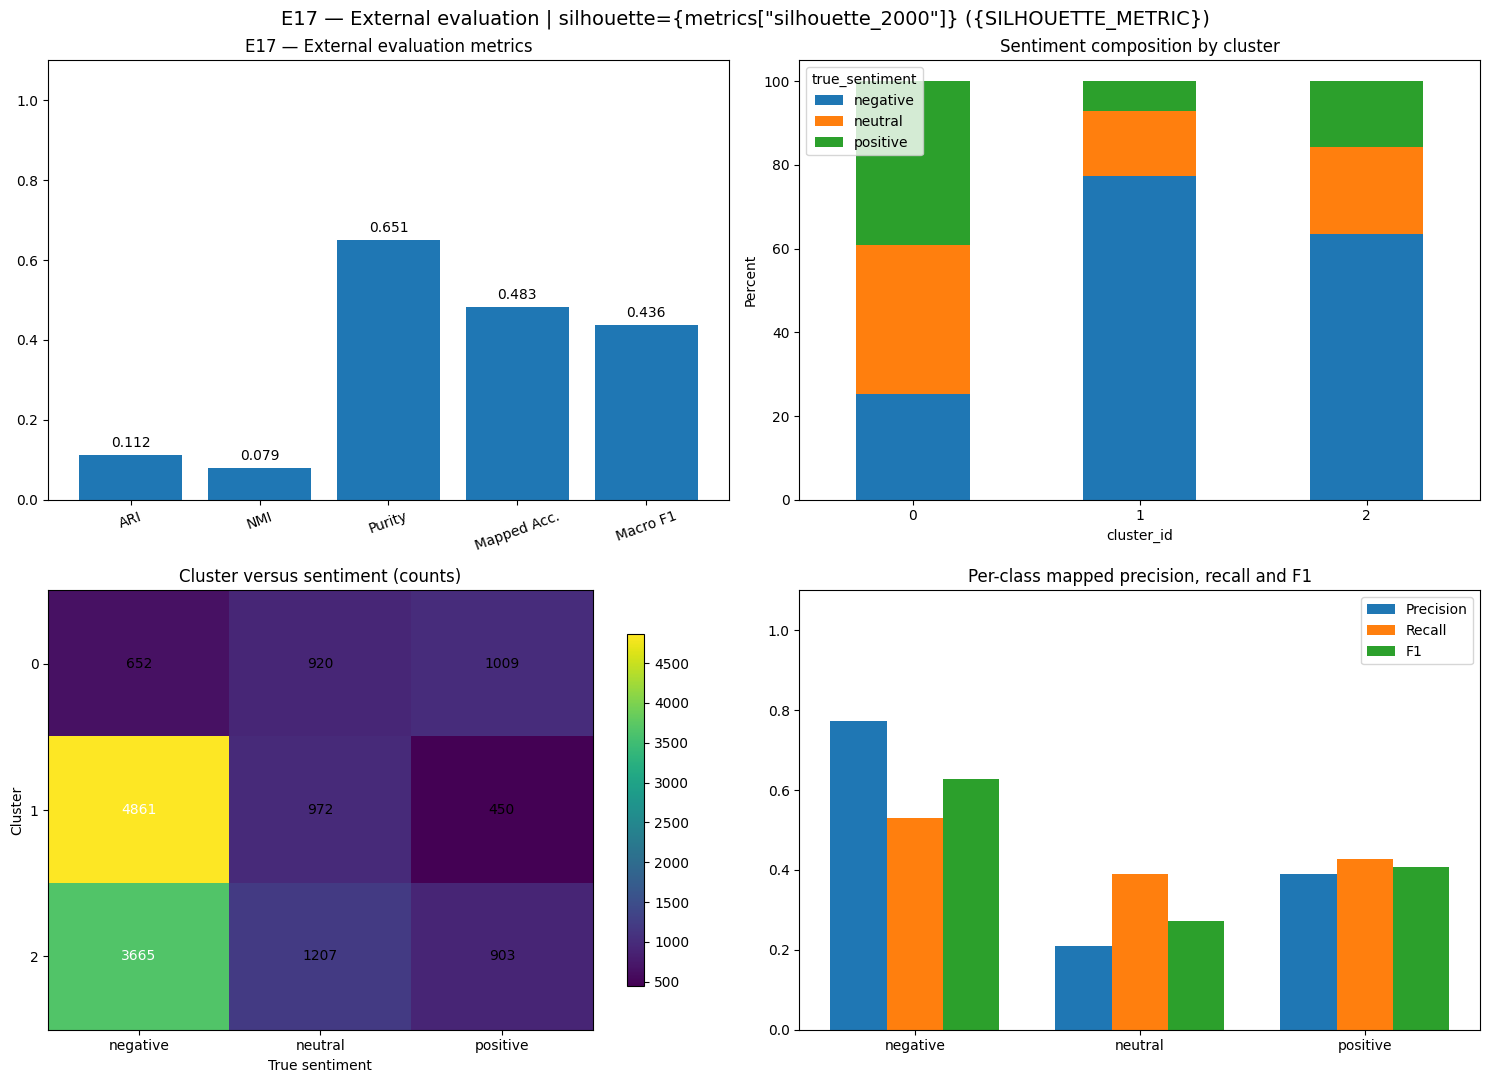

Saved: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E17/figures/E17_external_evaluation.png


In [13]:
# 13 — Four visual panels: scores, composition, contingency and per-class F1
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,2,figsize=(15,11))
keys=['ARI','NMI','Purity','Mapped Acc.','Macro F1']
vals=[metrics['ari'],metrics['nmi'],metrics['purity'],metrics['mapped_accuracy'],metrics['macro_f1']]
axes[0,0].bar(keys,vals);axes[0,0].set_ylim(0,1.1)
axes[0,0].set_title('E17 — External evaluation metrics')
axes[0,0].tick_params(axis='x',rotation=20)
for i,v in enumerate(vals): axes[0,0].text(i,v+0.02,f'{v:.3f}',ha='center')
(composition*100).plot(kind='bar',stacked=True,ax=axes[0,1])
axes[0,1].set_title('Sentiment composition by cluster')
axes[0,1].set_ylabel('Percent');axes[0,1].tick_params(axis='x',rotation=0)
mat=CONTINGENCY.to_numpy()
im=axes[1,0].imshow(mat,aspect='auto',cmap='viridis')
axes[1,0].set_xticks(range(3),CLASSES);axes[1,0].set_yticks(range(3),[0,1,2])
axes[1,0].set_xlabel('True sentiment');axes[1,0].set_ylabel('Cluster')
axes[1,0].set_title('Cluster versus sentiment (counts)')
for i in range(3):
    for j in range(3): axes[1,0].text(j,i,str(mat[i,j]),ha='center',va='center',color='white' if mat[i,j]>mat.max()/2 else 'black')
fig.colorbar(im,ax=axes[1,0],shrink=.8)
x=np.arange(3);w=.25
axes[1,1].bar(x-w,precision,w,label='Precision');axes[1,1].bar(x,recall,w,label='Recall');axes[1,1].bar(x+w,f1,w,label='F1')
axes[1,1].set_xticks(x,CLASSES);axes[1,1].set_ylim(0,1.1);axes[1,1].legend()
axes[1,1].set_title('Per-class mapped precision, recall and F1')
fig.suptitle('E17 — External evaluation | silhouette={metrics["silhouette_2000"]} ({SILHOUETTE_METRIC})',fontsize=14)
plt.tight_layout()
fig_dir=OUTPUT_DIR/'figures';fig_dir.mkdir(exist_ok=True,parents=True)
fig.savefig(fig_dir/'E17_external_evaluation.png',dpi=200,bbox_inches='tight')
plt.show()
print('Saved:',fig_dir/'E17_external_evaluation.png')